# 01 – Data exploration

**Goal of this notebook:** understand the Pork Rasher dataset (Roboflow, Version 4) before building any model.

It answers six questions, each of which affects a design decision later:

1. How many trays pass and fail? *(class balance → which metrics to report)*
2. Which defect types exist, and how often? *(→ pass/fail instead of defect-type classification)*
3. Is the official test set really unseen? *(near-duplicate check → can we trust the official split?)*
4. How big are the defects? *(→ what image resolution the CNN needs)*
5. Could a model "cheat" by counting how much meat is visible? *(→ shortcut check)*
6. How precise can results on an 80-photo test set be? *(→ report uncertainty)*

**To run:** put the unzipped Roboflow COCO export in `data/raw/` (so that `data/raw/train/_annotations.coco.json` exists), then run all cells. Takes about 1 minute.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

sys.path.insert(0, str(Path("..") / "src"))  # make the project's own code importable
from rasher_inspection.data import (FAIL, PASS, SPLITS, label_counts, load_dataset,
                                    nearest_neighbour_distance, one_per_source)
from rasher_inspection.features import meat_fraction, thumbnail

DATA_DIR = Path("../data/raw")       # Roboflow COCO export
RESULTS_DIR = Path("../results")     # figures are saved here for the report
RESULTS_DIR.mkdir(exist_ok=True)

# One colour per label, used in every figure of the project.
COLOURS = {"pass": "#2a78d6", "fail": "#eb6834"}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": "#898781", "ytick.color": "#898781",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "axes.axisbelow": True,
})

## 1. Load the labels

Every photo becomes an `ImageRecord` (see `src/rasher_inspection/data.py`). Its label is **FAIL** if it has at least one defect box, otherwise **PASS**.

Roboflow stores 3 exposure-shifted copies of each training photo, so we also count *original* photos.

In [2]:
data = load_dataset(DATA_DIR)

print(f"{'split':<6} {'photos':>7} {'originals':>10} {'pass':>6} {'fail':>6} {'% pass':>7}")
for split in SPLITS:
    recs = data[split]
    c = label_counts(recs)
    print(f"{split:<6} {len(recs):>7} {len(one_per_source(recs)):>10} {c['pass']:>6} {c['fail']:>6} "
          f"{100 * c['pass'] / len(recs):>6.1f}%")

split   photos  originals   pass   fail  % pass
train     3349       1085    684   2665   20.4%
valid      120        120     14    106   11.7%
test        80         80     12     68   15.0%


## 2. Class balance: most trays fail

Roughly 4 out of 5 photos contain a defect. A "model" that always answers FAIL would already score high accuracy, so **accuracy alone is misleading**. Later notebooks report balanced accuracy and the two kinds of mistake separately (missed defects vs good trays rejected), and use "always FAIL" as a trivial baseline.

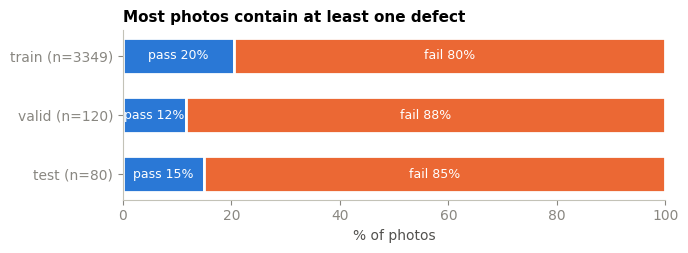

Accuracy of always answering FAIL on the official test set: 85.0%


In [3]:
fig, ax = plt.subplots(figsize=(7, 2.2))
for i, split in enumerate(SPLITS):
    c = label_counts(data[split])
    total = c["pass"] + c["fail"]
    left = 0
    for name in ("pass", "fail"):
        share = 100 * c[name] / total
        ax.barh(i, share, left=left, height=0.6, color=COLOURS[name], edgecolor="white", linewidth=2)
        ax.text(left + share / 2, i, f"{name} {share:.0f}%", ha="center", va="center", color="white", fontsize=9)
        left += share
ax.set_yticks(range(len(SPLITS)), [f"{s} (n={len(data[s])})" for s in SPLITS])
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("% of photos")
ax.grid(False)
ax.set_title("Most photos contain at least one defect")
fig.savefig(RESULTS_DIR / "01_class_balance.png")
plt.show()

always_fail_acc = label_counts(data["test"])["fail"] / len(data["test"])
print(f"Accuracy of always answering FAIL on the official test set: {always_fail_acc:.1%}")

## 3. Defect types: some are too rare to learn

Counted once per original photo (augmented copies would triple the training counts).

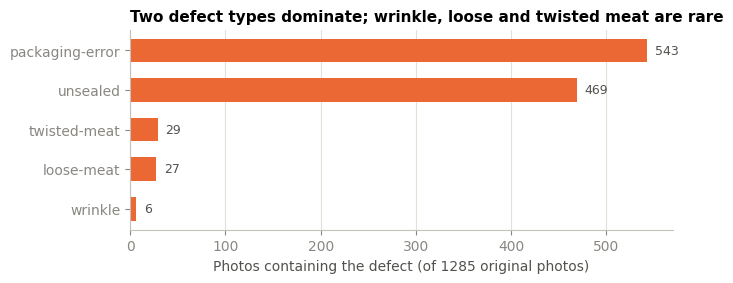

In [4]:
originals = [r for split in SPLITS for r in one_per_source(data[split])]

classes = sorted({d for r in originals for d in r.defects})
n_with = {c: sum(c in r.defects for r in originals) for c in classes}
order = sorted(classes, key=n_with.get)

fig, ax = plt.subplots(figsize=(7, 2.6))
ax.barh(order, [n_with[c] for c in order], height=0.6, color=COLOURS["fail"])
for y, c in enumerate(order):
    ax.text(n_with[c] + 8, y, str(n_with[c]), va="center", color="#52514e", fontsize=9)
ax.set_xlabel(f"Photos containing the defect (of {len(originals)} original photos)")
ax.grid(axis="y", visible=False)
ax.set_title("Two defect types dominate; wrinkle, loose and twisted meat are rare")
fig.savefig(RESULTS_DIR / "01_defect_types.png")
plt.show()

With only a few dozen examples of wrinkle, loose meat and twisted meat, a model could not learn to tell defect *types* apart reliably. This supports the project's scope: a single **pass/fail** decision per tray.

## 4. Is the official test set really unseen?

The photos come from a fixed camera over a conveyor belt, so many look alike. If the random official split had put copies (or near-copies) of test photos into the training set, test results would be too optimistic.

**Method:** shrink every photo to a 48×36 greyscale thumbnail, normalise its brightness (`features.thumbnail`), and measure the mean absolute difference between thumbnails. For each test and validation photo we find its closest training photo, and compare that distance with two references:

* **same photo, different exposure** – two Roboflow copies of one training photo (what a duplicate looks like);
* **two random training photos** (what unrelated photos look like).

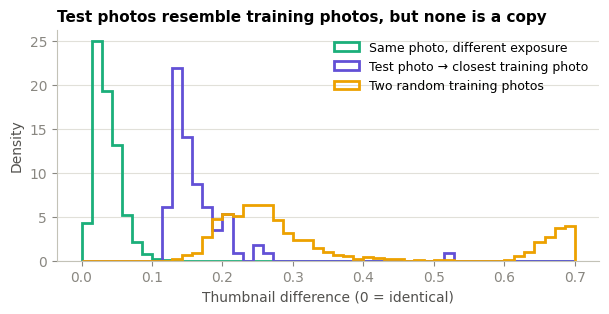

Median difference – same photo: 0.033, test→closest train: 0.148, random: 0.320
valid: 0 of 120 photos are as close to a training photo as two copies of one photo (threshold 0.088); closest = 0.110
test: 0 of 80 photos are as close to a training photo as two copies of one photo (threshold 0.088); closest = 0.115


In [5]:
thumbs = {split: np.stack([thumbnail(r.path) for r in data[split]]) for split in SPLITS}

# Reference 1: pairs of augmented copies of the same original training photo.
# A few names appear 6 times (two different photos share a name), so only
# names with exactly 3 copies are used here.
from collections import Counter
n_copies = Counter(r.source for r in data["train"])
first_copy = {}
copy_pairs = []
for i, r in enumerate(data["train"]):
    if n_copies[r.source] != 3:
        continue
    if r.source in first_copy:
        copy_pairs.append((first_copy[r.source], i))
    else:
        first_copy[r.source] = i
same_photo = np.array([np.abs(thumbs["train"][i] - thumbs["train"][j]).mean() for i, j in copy_pairs])

# Reference 2: random pairs of different training photos.
rng = np.random.default_rng(0)
pairs = [(i, j) for i, j in rng.integers(0, len(data["train"]), size=(2000, 2))
         if data["train"][i].source != data["train"][j].source][:1000]
random_pairs = np.array([np.abs(thumbs["train"][i] - thumbs["train"][j]).mean() for i, j in pairs])

# The check: distance from each test/valid photo to its closest training photo.
nearest = {s: nearest_neighbour_distance(thumbs[s], thumbs["train"]) for s in ("valid", "test")}

fig, ax = plt.subplots(figsize=(7, 3))
bins = np.linspace(0, 0.7, 50)
series = [("Same photo, different exposure", same_photo, "#1baf7a"),
          ("Test photo → closest training photo", nearest["test"], "#6250d6"),
          ("Two random training photos", random_pairs, "#eda100")]
for name, values, colour in series:
    ax.hist(values, bins=bins, density=True, histtype="step", linewidth=2, color=colour, label=name)
ax.legend(frameon=False, fontsize=9)
ax.set_xlabel("Thumbnail difference (0 = identical)")
ax.set_ylabel("Density")
ax.grid(axis="x", visible=False)
ax.set_title("Test photos resemble training photos, but none is a copy")
fig.savefig(RESULTS_DIR / "01_near_duplicate_check.png")
plt.show()

threshold = np.percentile(same_photo, 99)
print(f"Median difference – same photo: {np.median(same_photo):.3f}, "
      f"test→closest train: {np.median(nearest['test']):.3f}, random: {np.median(random_pairs):.3f}")
for s in ("valid", "test"):
    n_dup = int(np.sum(nearest[s] <= threshold))
    print(f"{s}: {n_dup} of {len(nearest[s])} photos are as close to a training photo as two copies of one photo "
          f"(threshold {threshold:.3f}); closest = {nearest[s].min():.3f}")

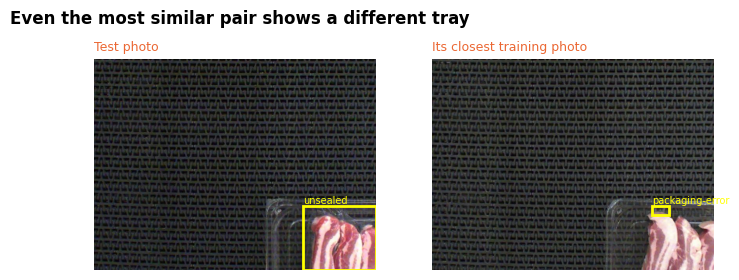

In [6]:
def show_photo(ax, record, title=None):
    # Draw a photo with its defect boxes (yellow) and a PASS/FAIL tag.
    ax.imshow(Image.open(record.path))
    for (x, y, w, h), name in zip(record.boxes, record.defects):
        ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, edgecolor="yellow", linewidth=2))
        ax.text(x, y - 6, name, color="yellow", fontsize=7)
    tag = "FAIL" if record.label == FAIL else "PASS"
    ax.set_title(title or f"{record.split} · {tag}", fontsize=9, fontweight="normal", color=COLOURS[tag.lower()])
    ax.axis("off")

# The most similar test/training pair in the whole dataset.
i = int(np.argmin(nearest["test"]))
j = int(np.argmin(np.abs(thumbs["train"] - thumbs["test"][i]).mean(axis=1)))
fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
show_photo(axes[0], data["test"][i], "Test photo")
show_photo(axes[1], data["train"][j], "Its closest training photo")
fig.suptitle("Even the most similar pair shows a different tray", x=0.02, ha="left", fontweight="bold")
fig.savefig(RESULTS_DIR / "01_closest_pair.png")
plt.show()

**Conclusion:** the closest training photo to any test photo is much more different than two copies of the same photo, so the official split contains **no duplicates** and can be used as it is. Test photos are, however, much more similar to training photos than two random photos are – everything was filmed with the same camera, belt and lighting. Results will therefore describe performance *on this production line*, not on other cameras or factories (a limitation for the report).

*Side note:* the file names contain a number (`frame_with_red_8214`), but photos with neighbouring numbers are not similar, so the numbers do not tell us which photos were taken close together in time.

## 5. What PASS and FAIL photos look like

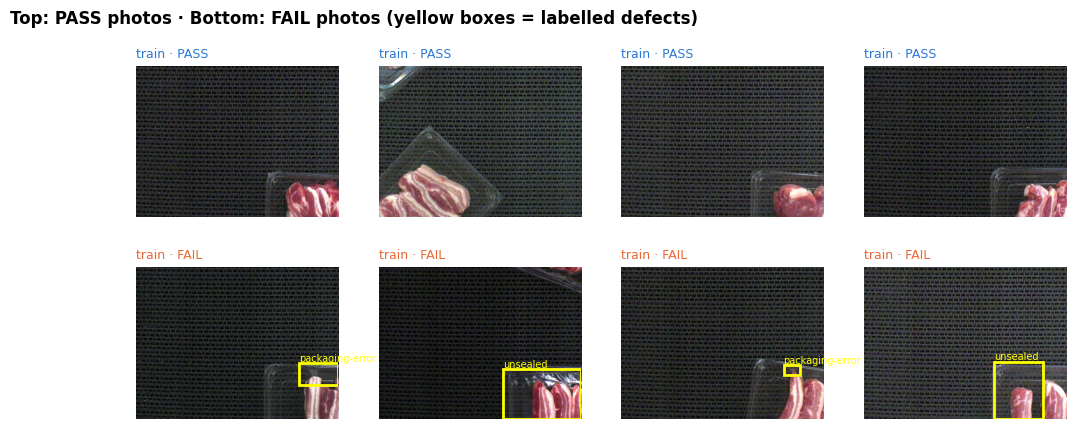

In [7]:
rng = np.random.default_rng(0)
pass_photos = [r for r in originals if r.label == PASS]
fail_photos = [r for r in originals if r.label == FAIL]
sample = ([pass_photos[i] for i in rng.choice(len(pass_photos), 4, replace=False)]
          + [fail_photos[i] for i in rng.choice(len(fail_photos), 4, replace=False)])

fig, axes = plt.subplots(2, 4, figsize=(12, 4.8))
for ax, r in zip(axes.flat, sample):
    show_photo(ax, r)
fig.suptitle("Top: PASS photos · Bottom: FAIL photos (yellow boxes = labelled defects)", x=0.02, ha="left", fontweight="bold")
fig.savefig(RESULTS_DIR / "01_examples.png")
plt.show()

Note that the camera often sees only **part of a tray** as it enters or leaves the picture. So "PASS" really means *no defect visible in this photo*, not *this tray is fine*. This is an important limitation for the report.

## 6. How big are the defects?

CNNs usually work on small images (MobileNetV2 is designed for 224 pixels wide). If a defect shrinks to a few pixels it may become invisible. Box side length = √(width × height), counted once per original photo.

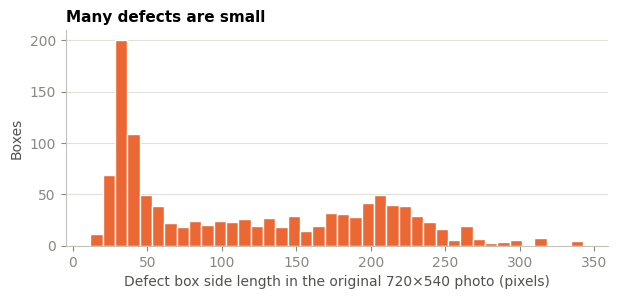

1150 boxes; median side 99 px, smallest 12 px

Share of boxes smaller than 10 px after resizing the photo to a given width:
  224 px wide: 14.8%
  320 px wide:  1.9%
  448 px wide:  0.3%
  720 px wide:  0.0%


In [8]:
sides = np.array([np.sqrt(w * h) for r in originals for (_, _, w, h) in r.boxes])

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.hist(sides, bins=40, color=COLOURS["fail"], edgecolor="white", linewidth=1)
ax.set_xlabel("Defect box side length in the original 720×540 photo (pixels)")
ax.set_ylabel("Boxes")
ax.grid(axis="x", visible=False)
ax.set_title("Many defects are small")
fig.savefig(RESULTS_DIR / "01_defect_sizes.png")
plt.show()

print(f"{len(sides)} boxes; median side {np.median(sides):.0f} px, smallest {sides.min():.0f} px")
print("\nShare of boxes smaller than 10 px after resizing the photo to a given width:")
for width in (224, 320, 448, 720):
    scaled = sides * width / 720
    print(f"  {width:>3} px wide: {np.mean(scaled < 10):5.1%}")

This motivates the **resolution experiment** in the CNN notebook (train at 224 px and at a larger size, and compare accuracy against speed).

## 7. Shortcut check: does the amount of visible meat give the answer away?

If PASS photos simply showed less meat (e.g. trays half out of view), a model could score well without learning anything about defects. We measure the fraction of red/pink pixels in every original photo (`features.meat_fraction`) and see how well that single number separates PASS from FAIL.

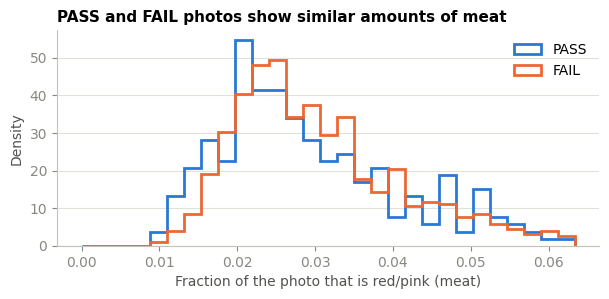

Best balanced accuracy from meat fraction alone: 54.9% (50% = guessing)


In [9]:
fractions = np.array([meat_fraction(r.path) for r in originals])
labels = np.array([r.label for r in originals])

fig, ax = plt.subplots(figsize=(7, 2.8))
bins = np.linspace(0, np.percentile(fractions, 99), 30)
for name, lab in (("pass", PASS), ("fail", FAIL)):
    ax.hist(fractions[labels == lab], bins=bins, density=True, histtype="step",
            linewidth=2, color=COLOURS[name], label=name.upper())
ax.legend(frameon=False)
ax.set_xlabel("Fraction of the photo that is red/pink (meat)")
ax.set_ylabel("Density")
ax.grid(axis="x", visible=False)
ax.set_title("PASS and FAIL photos show similar amounts of meat")
fig.savefig(RESULTS_DIR / "01_meat_fraction.png")
plt.show()

# Best possible balanced accuracy using a single threshold on this number.
def balanced_accuracy(threshold):
    pass_correct = np.mean(fractions[labels == PASS] < threshold)
    fail_correct = np.mean(fractions[labels == FAIL] >= threshold)
    return (pass_correct + fail_correct) / 2

best = max(np.unique(fractions), key=balanced_accuracy)
print(f"Best balanced accuracy from meat fraction alone: {balanced_accuracy(best):.1%} (50% = guessing)")

The amount of visible meat barely separates the classes (close to the 50% of guessing), so there is no obvious shortcut. It also suggests that simple **colour** information carries little signal about defects, which is a useful expectation for the colour-histogram baseline.

## 8. How precise can results on the official test set be?

The test set has only 80 photos, of which just 12 are PASS. We can estimate how uncertain a result will be with the Wilson 95% confidence interval for a proportion.

In [10]:
def wilson_interval(successes, n, z=1.96):
    # 95% confidence interval for a proportion (Wilson score method).
    p = successes / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

# Example: what if a model got 72 of 80 test photos right, 9 of the 12 PASS and 63 of the 68 FAIL?
c = label_counts(data["test"])
examples = [("Accuracy, 72 of 80 correct", 72, 80),
            (f"PASS recognised, 9 of {c['pass']}", 9, c["pass"]),
            (f"FAIL caught, 63 of {c['fail']}", 63, c["fail"])]
print("Example model:")
for text, k, n in examples:
    lo, hi = wilson_interval(k, n)
    print(f"  {text:<28} = {k / n:5.1%}   95% CI {lo:5.1%} – {hi:5.1%}")
print(f"\nEach PASS test photo is worth {100 / c['pass']:.1f} percentage points of PASS recall.")

Example model:
  Accuracy, 72 of 80 correct   = 90.0%   95% CI 81.5% – 94.8%
  PASS recognised, 9 of 12     = 75.0%   95% CI 46.8% – 91.1%
  FAIL caught, 63 of 68        = 92.6%   95% CI 83.9% – 96.8%

Each PASS test photo is worth 8.3 percentage points of PASS recall.


With only 12 PASS photos, the PASS recall of any model will be uncertain by roughly ±20 percentage points. Every result in this project is therefore reported **with a 95% confidence interval**, and differences between models smaller than that are not treated as meaningful. The validation set (120 photos) is used for model choices, so the test set is only used once, at the end.

## Summary – findings to carry into the report

| # | Finding | Decision |
|---|---|---|
| 1 | ~80% of photos are FAIL; "always FAIL" scores 85% accuracy on the test set | Report balanced accuracy, missed defects and false rejects; include "always FAIL" as a trivial baseline |
| 2 | Wrinkle, loose meat and twisted meat appear in very few photos | Classify **pass/fail** only |
| 3 | No near-duplicates between train and test, but all photos come from one camera and belt | Use the **official split**; results apply to this line only |
| 4 | Many defects shrink below 10 px at 224 px width | Compare CNN input resolutions |
| 5 | Visible meat area barely separates PASS from FAIL | No obvious shortcut; colour alone is likely a weak signal |
| 6 | Test set has only 12 PASS photos | Report 95% confidence intervals with every result |
| – | Partial trays: PASS means "no defect visible in this photo" | State as a limitation |